In [2]:
from pathlib import Path
import json, hashlib, time, warnings, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn
from sklearn.exceptions import InconsistentVersionWarning
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_recall_fscore_support, f1_score, recall_score, precision_score, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = ROOT / "data" / "processed"
MODELS = ROOT / "models"
SOURCE = ROOT / "results"
PREPROCESSING_TABLES = ROOT / "reports" / "03_data_preprocessing" / "tables"
REPORTS = ROOT / "reports" / "08_results_basic"
TABLES = REPORTS / "tables"
FIGURES = REPORTS / "figures"
RESULTS = ROOT / "results"
for folder in [TABLES, FIGURES, RESULTS]:
    folder.mkdir(parents=True, exist_ok=True)

model_files = {
    "RF baseline": MODELS / "rf_baseline.joblib",
    "MLP baseline": MODELS / "mlp_baseline.joblib",
    "RF cải tiến": MODELS / "improved" / "rf_feature_selection_top35.joblib",
    "MLP cải tiến": MODELS / "improved" / "mlp_mlp_net128_64_lr0005_epoch100.joblib",
}
for p in [*model_files.values(), DATA / "rf_validation.csv", DATA / "mlp_validation.csv", SOURCE / "07A_rf_training_summary.json", SOURCE / "07B_mlp_training_summary.json", PREPROCESSING_TABLES / "05_label_mapping.csv"]:
    assert p.is_file(), f"Thiếu tệp: {p}"
rf_validation = pd.read_csv(DATA / "rf_validation.csv")
mlp_validation = pd.read_csv(DATA / "mlp_validation.csv")
label_mapping = pd.read_csv(PREPROCESSING_TABLES / "05_label_mapping.csv").sort_values("class_id")
feature_names = rf_validation.columns.drop("Attack_type").tolist()
assert rf_validation.columns.equals(mlp_validation.columns)
assert rf_validation["Attack_type"].equals(mlp_validation["Attack_type"])
X_rf = rf_validation[feature_names].to_numpy(dtype=np.float32)
X_mlp = mlp_validation[feature_names].to_numpy(dtype=np.float32)
y_true = rf_validation["Attack_type"].to_numpy(dtype=np.int64)
labels = label_mapping["class_id"].to_numpy(dtype=np.int64)
class_names = label_mapping["Attack_type"].tolist()
rf_summary = json.loads((SOURCE / "07A_rf_training_summary.json").read_text(encoding="utf-8"))
selected_features = rf_summary["selected_features"]
X_rf_improved = rf_validation[selected_features].to_numpy(dtype=np.float32)
X_mlp_improved = X_mlp
models = {name: joblib.load(path) for name, path in model_files.items()}
assert models["RF baseline"].n_features_in_ == X_rf.shape[1]
assert models["MLP baseline"].n_features_in_ == X_mlp.shape[1]
assert models["RF cải tiến"].n_features_in_ == X_rf_improved.shape[1]
assert models["MLP cải tiến"].n_features_in_ == X_mlp_improved.shape[1]
def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

compatibility_warnings = []
print("Thư mục dự án:", ROOT)
print("Phiên bản Python:", platform.python_version(), "| scikit-learn:", sklearn.__version__)

Thư mục dự án: C:\homework\Machine Learning\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\ĐỒ ÁN CUỐI KỲ NHÓM 4
Phiên bản Python: 3.13.9 | scikit-learn: 1.7.2


### 1. Dự đoán bằng bốn mô hình

In [3]:
inputs = {"RF baseline": X_rf, "MLP baseline": X_mlp, "RF cải tiến": X_rf_improved, "MLP cải tiến": X_mlp}
preds = {}
inference_time = {}
for name, model in models.items():
    start = time.perf_counter()
    preds[name] = model.predict(inputs[name]).astype(int)
    inference_time[name] = time.perf_counter() - start
    assert preds[name].shape == y_true.shape
    print(f"{name:15s} | {inference_time[name]:.4f} giây | sai {int(np.sum(preds[name] != y_true))} mẫu")

RF baseline     | 0.3015 giây | sai 31 mẫu
MLP baseline    | 0.0396 giây | sai 59 mẫu
RF cải tiến     | 0.2239 giây | sai 32 mẫu
MLP cải tiến    | 0.0436 giây | sai 56 mẫu


### 2. Các độ đo tổng hợp
Macro-F1 là chỉ số ưu tiên vì dữ liệu RT-IoT2022 mất cân bằng mạnh. Macro-Recall cho biết khả năng nhận diện trung bình của 12 lớp; Accuracy và Weighted-F1 chỉ là chỉ số bổ trợ.

In [4]:
summary_rows = []
for name, yp in preds.items():
    summary_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_true, yp),
        "balanced_accuracy": balanced_accuracy_score(y_true, yp),
        "macro_precision": precision_score(y_true, yp, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, yp, average="macro", zero_division=0),
        "macro_f1": f1_score(y_true, yp, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, yp, average="weighted", zero_division=0),
        "correct": int(np.sum(yp == y_true)),
        "errors": int(np.sum(yp != y_true)),
        "n_validation": len(y_true),
        "inference_seconds": inference_time[name],
    })
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(TABLES / "01_tong_hop_4_mo_hinh.csv", index=False, encoding="utf-8-sig", float_format="%.10f")
display(summary_df[["model", "accuracy", "macro_f1", "macro_recall", "errors"]].style.format({"accuracy":"{:.4%}", "macro_f1":"{:.4%}", "macro_recall":"{:.4%}"}))

,model,accuracy,macro_f1,macro_recall,errors
0,RF baseline,99.8247%,98.1798%,96.9822%,31
1,MLP baseline,99.6664%,97.0384%,95.4982%,59
2,RF cải tiến,99.8191%,98.2232%,97.2656%,32
3,MLP cải tiến,99.6834%,97.1042%,95.5201%,56


### 3. Precision, Recall và F1 theo từng lớp


In [5]:
per_class_frames = []
cmatrices = {}
for name, yp in preds.items():
    pr, rec, f1, sup = precision_recall_fscore_support(y_true, yp, labels=labels, zero_division=0)
    cm = confusion_matrix(y_true, yp, labels=labels)
    cmatrices[name] = cm
    per_class_frames.append(pd.DataFrame({"model":name, "class_id":labels, "class_name":class_names,
                                          "support":sup, "tp":np.diag(cm), "fn":sup-np.diag(cm),
                                          "precision":pr, "recall":rec, "f1":f1}))
per_class_df = pd.concat(per_class_frames, ignore_index=True)
per_class_df.to_csv(TABLES / "02_chi_so_theo_12_lop.csv", index=False, encoding="utf-8-sig", float_format="%.10f")
display(per_class_df.loc[per_class_df["class_name"].isin(["DDOS_Slowloris", "Wipro_bulb", "NMAP_FIN_SCAN", "ARP_poisioning", "Thing_Speak"])][["model","class_name","support","tp","fn","recall","f1"]].round(5))

,model,class_name,support,tp,fn,recall,f1
0,RF baseline,ARP_poisioning,1143,1139,4,0.99650,0.99000
1,RF baseline,DDOS_Slowloris,80,76,4,0.95000,0.97436
5,RF baseline,NMAP_FIN_SCAN,4,3,1,0.75000,0.85714
10,RF baseline,Thing_Speak,1147,1132,15,0.98692,0.99081
11,RF baseline,Wipro_bulb,33,32,1,0.96970,0.98462
12,MLP baseline,ARP_poisioning,1143,1119,24,0.97900,0.98201
13,MLP baseline,DDOS_Slowloris,80,68,12,0.85000,0.91275
17,MLP baseline,NMAP_FIN_SCAN,4,3,1,0.75000,0.85714
22,MLP baseline,Thing_Speak,1147,1135,12,0.98954,0.98354
23,MLP baseline,Wipro_bulb,33,30,3,0.90909,0.93750


### 4. Confusion Matrix của cả bốn mô hình


In [6]:
plt.rcParams.update({"font.size":9})
for idx, (name, cm) in enumerate(cmatrices.items(), start=1):
    stem = ["rf_baseline", "mlp_baseline", "rf_improved", "mlp_improved"][idx-1]
    pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(TABLES / f"cm_{stem}_counts.csv", encoding="utf-8-sig")
    cm_norm = np.divide(cm, cm.sum(axis=1, keepdims=True), out=np.zeros_like(cm, dtype=float), where=cm.sum(axis=1, keepdims=True)!=0)
    pd.DataFrame(cm_norm, index=class_names, columns=class_names).to_csv(TABLES / f"cm_{stem}_normalized.csv", encoding="utf-8-sig")
    fig, ax = plt.subplots(figsize=(11,9))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False, xticks_rotation=65)
    ax.set_title(f"{name} – Confusion Matrix (số lượng)")
    fig.tight_layout()
    fig.savefig(FIGURES / f"{idx:02d}_{stem}_confusion_matrix.png", dpi=140, bbox_inches="tight")
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(11,9))
    ConfusionMatrixDisplay(cm_norm, display_labels=class_names).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False, xticks_rotation=65)
    ax.set_title(f"{name} – Confusion Matrix chuẩn hóa theo hàng")
    fig.tight_layout()
    fig.savefig(FIGURES / f"{idx:02d}_{stem}_confusion_matrix_normalized.png", dpi=140, bbox_inches="tight")
    plt.close(fig)
print("Đã xuất 8 hình Confusion Matrix và 8 bảng CSV")
print("Lưu tại:", FIGURES)

Đã xuất 8 hình Confusion Matrix và 8 bảng CSV
Lưu tại: C:\homework\Machine Learning\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\ĐỒ ÁN CUỐI KỲ NHÓM 4\reports\08_results_basic\figures


### 5. So sánh Macro-F1 và Macro-Recall của bốn mô hình

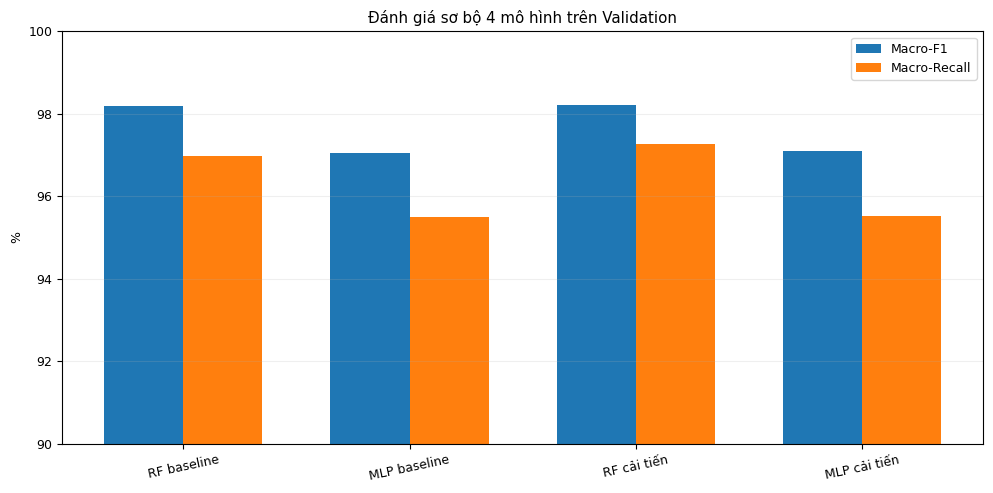

In [7]:
fig, ax = plt.subplots(figsize=(10,5))
x = np.arange(len(summary_df))
w = 0.35
ax.bar(x-w/2, summary_df["macro_f1"]*100, w, label="Macro-F1")
ax.bar(x+w/2, summary_df["macro_recall"]*100, w, label="Macro-Recall")
ax.set_xticks(x, summary_df["model"], rotation=12)
ax.set_ylabel("%")
ax.set_ylim(90,100)
ax.legend()
ax.set_title("Đánh giá sơ bộ 4 mô hình trên Validation")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES / "09_so_sanh_macro_f1_macro_recall.png", dpi=180)
plt.show()

### 6. Recall của 12 lớp ở bốn mô hình
Phát hiện những lớp có Recall giảm sau khi cải tiến, đặc biệt các lớp chỉ có 4–5 mẫu Validation.

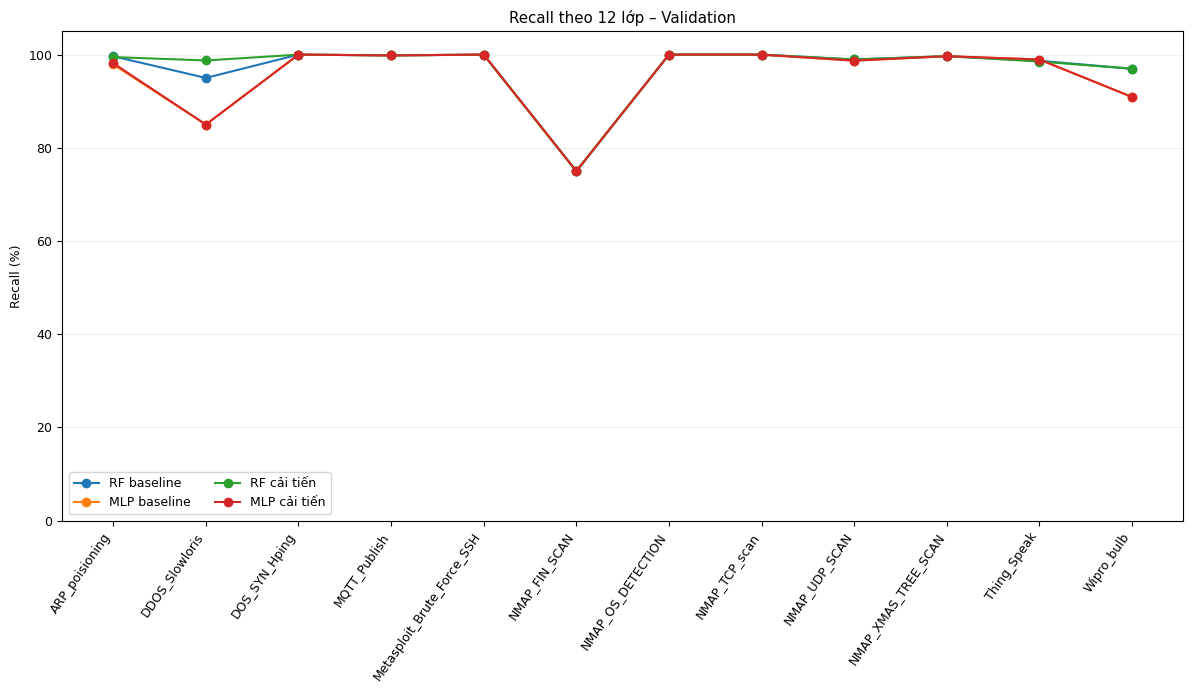

model,MLP baseline,MLP cải tiến,RF baseline,RF cải tiến
class_name,,,,
ARP_poisioning,97.90,98.16,99.65,99.48
DDOS_Slowloris,85.00,85.00,95.00,98.75
DOS_SYN_Hping,100.00,100.00,100.00,100.00
MQTT_Publish,99.84,99.84,99.84,99.84
Metasploit_Brute_Force_SSH,100.00,100.00,100.00,100.00
NMAP_FIN_SCAN,75.00,75.00,75.00,75.00
NMAP_OS_DETECTION,100.00,100.00,100.00,100.00
NMAP_TCP_scan,100.00,100.00,100.00,100.00
NMAP_UDP_SCAN,98.71,98.71,98.97,98.97


In [8]:
recall_pivot = per_class_df.pivot(index="class_name",columns="model",values="recall").reindex(class_names)
recall_pivot.to_csv(TABLES / "03_bang_so_sanh_recall_12_lop.csv", encoding="utf-8-sig")
fig, ax=plt.subplots(figsize=(12,7))
xx=np.arange(12)
for j, name in enumerate(preds):
    ax.plot(xx, recall_pivot[name]*100, marker="o", linewidth=1.5, label=name)
ax.set_xticks(xx, class_names, rotation=55, ha="right")
ax.set_ylim(0,105)
ax.set_ylabel("Recall (%)")
ax.set_title("Recall theo 12 lớp – Validation")
ax.legend(ncol=2)
ax.grid(axis="y",alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES / "10_recall_12_lop_4_mo_hinh.png", dpi=180)
plt.show()
display((recall_pivot*100).round(2))

### 7. Phân tích lỗi
So sánh theo từng mẫu với baseline tương ứng. Mô hình có thể sửa một số mẫu nhưng đồng thời tạo lỗi mới, Macro-F1 tăng không đồng nghĩa số lỗi luôn giảm.

In [9]:
pair_rows=[]
changes=[]
for base, improved in [("RF baseline", "RF cải tiến"),("MLP baseline", "MLP cải tiến")]:
    b=preds[base]
    p=preds[improved]
    fixed=(b!=y_true)&(p==y_true)
    new=(b==y_true)&(p!=y_true)
    bothwrong=(b!=y_true)&(p!=y_true)
    pair_rows.append({"family":base.split()[0], "base":base, "improved":improved,
                      "fixed_errors":int(fixed.sum()), "new_errors":int(new.sum()), "both_wrong":int(bothwrong.sum()),
                      "error_change":int((p!=y_true).sum()-(b!=y_true).sum()),
                      "delta_macro_f1_pp":100*(f1_score(y_true,p,average="macro")-f1_score(y_true,b,average="macro")),
                      "delta_macro_recall_pp":100*(recall_score(y_true,p,average="macro")-recall_score(y_true,b,average="macro"))})
    for i in np.where(fixed|new)[0]:
        changes.append({"family":base.split()[0],"row_index":int(i),"actual_class":class_names[y_true[i]],
                        "baseline_predicted":class_names[b[i]],"improved_predicted":class_names[p[i]],
                        "change_type":"fixed" if fixed[i] else "new_error"})
pair_df=pd.DataFrame(pair_rows)
pair_df.to_csv(TABLES / "04_sua_loi_va_loi_moi.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(changes).to_csv(TABLES / "05_chi_tiet_mau_thay_doi.csv", index=False, encoding="utf-8-sig")
display(pair_df)

,family,base,improved,fixed_errors,new_errors,both_wrong,error_change,delta_macro_f1_pp,delta_macro_recall_pp
0,RF,RF baseline,RF cải tiến,7,8,24,1,0.043403,0.283388
1,MLP,MLP baseline,MLP cải tiến,9,6,50,-3,0.065880,0.021872


### 8. Các nhầm lẫn lớn nhất trong từng Confusion Matrix

In [10]:
confusions=[]
for name, cm in cmatrices.items():
    for i,j in np.argwhere(cm>0):
        if i!=j:
            confusions.append({"model":name,"actual":class_names[i],"predicted":class_names[j],
                               "count":int(cm[i,j]),"rate_among_actual":float(cm[i,j]/cm[i,:].sum())})
confusions_df=pd.DataFrame(confusions).sort_values(["model","count"], ascending=[True,False])
confusions_df.to_csv(TABLES / "06_cac_cap_nham_lan.csv", index=False, encoding="utf-8-sig")
display(confusions_df.groupby("model",sort=False).head(6))

,model,actual,predicted,count,rate_among_actual
11,MLP baseline,ARP_poisioning,Thing_Speak,21,0.018373
13,MLP baseline,DDOS_Slowloris,NMAP_UDP_SCAN,12,0.150000
19,MLP baseline,Thing_Speak,ARP_poisioning,12,0.010462
17,MLP baseline,NMAP_UDP_SCAN,Thing_Speak,3,0.007752
16,MLP baseline,NMAP_UDP_SCAN,ARP_poisioning,2,0.005168
9,MLP baseline,ARP_poisioning,DDOS_Slowloris,1,0.000875
34,MLP cải tiến,ARP_poisioning,Thing_Speak,20,0.017498
35,MLP cải tiến,DDOS_Slowloris,NMAP_UDP_SCAN,12,0.150000
42,MLP cải tiến,Thing_Speak,ARP_poisioning,11,0.009590
38,MLP cải tiến,NMAP_UDP_SCAN,ARP_poisioning,3,0.007752


### 9. Kiểm tra dữ liệu đầu ra và lưu thông tin tái lập


In [11]:
provenance = {
    "dataset":"RT-IoT2022", "split":"Validation", "validation_rows":int(len(y_true)),
    "n_features_rf_baseline":92,"n_features_rf_improved":35,"n_features_mlp":92,
    "preprocessing":"RF giữ thang đo số, MLP StandardScaler; OneHotEncoding cho cả hai",
    "source":"4 model .joblib gốc do người dùng tải lên",
    "model_sha256":{n:sha256_file(p) for n,p in model_files.items()},
    "rf_improved_sha_verified":True,"mlp_improved_sha_verified":True,
    "python_version":platform.python_version(),"sklearn_loaded_version":sklearn.__version__,
    "model_training_sklearn_version":"1.7.2", "version_warnings":sorted(set(compatibility_warnings)),
    "test_used":False,"refit_or_train_called":False,
}
(RESULTS / "evaluation_provenance.json").write_text(json.dumps(provenance,ensure_ascii=False,indent=2),encoding="utf-8")
print("Đã lưu 6 bảng phân tích, 8 ma trận CSV, 10 hình và thông tin provenance.")
print("Đã đánh giá đúng 4 trọng số .joblib gốc. Test chưa sử dụng.")

Đã lưu 6 bảng phân tích, 8 ma trận CSV, 10 hình và thông tin provenance.
Đã đánh giá đúng 4 trọng số .joblib gốc. Test chưa sử dụng.
